# Первичный анализ датасета
На данном этапе проводится первичное знакомство с датасетом
`Default of Credit Card Clients Dataset`.


In [39]:
# Импортируем необходимые библиотеки
import pandas as pd
import numpy as np
from pathlib import Path
import matplotlib.pyplot as plt
import great_expectations as gx

In [17]:
# Загрузка исходных данных. Используем относительный путь, чтобы код не зависел от абсолютного пути

data_path = "../data/raw/UCI_Credit_Card.csv"
df = pd.read_csv(data_path)
df.head(10)

,ID,LIMIT_BAL,SEX,EDUCATION,MARRIAGE,AGE,PAY_0,PAY_2,PAY_3,PAY_4,...,BILL_AMT4,BILL_AMT5,BILL_AMT6,PAY_AMT1,PAY_AMT2,PAY_AMT3,PAY_AMT4,PAY_AMT5,PAY_AMT6,default.payment.next.month
0,1,20000.0,2,2,1,24,2,2,-1,-1,...,0.0,0.0,0.0,0.0,689.0,0.0,0.0,0.0,0.0,1
1,2,120000.0,2,2,2,26,-1,2,0,0,...,3272.0,3455.0,3261.0,0.0,1000.0,1000.0,1000.0,0.0,2000.0,1
2,3,90000.0,2,2,2,34,0,0,0,0,...,14331.0,14948.0,15549.0,1518.0,1500.0,1000.0,1000.0,1000.0,5000.0,0
3,4,50000.0,2,2,1,37,0,0,0,0,...,28314.0,28959.0,29547.0,2000.0,2019.0,1200.0,1100.0,1069.0,1000.0,0
4,5,50000.0,1,2,1,57,-1,0,-1,0,...,20940.0,19146.0,19131.0,2000.0,36681.0,10000.0,9000.0,689.0,679.0,0
5,6,50000.0,1,1,2,37,0,0,0,0,...,19394.0,19619.0,20024.0,2500.0,1815.0,657.0,1000.0,1000.0,800.0,0
6,7,500000.0,1,1,2,29,0,0,0,0,...,542653.0,483003.0,473944.0,55000.0,40000.0,38000.0,20239.0,13750.0,13770.0,0
7,8,100000.0,2,2,2,23,0,-1,-1,0,...,221.0,-159.0,567.0,380.0,601.0,0.0,581.0,1687.0,1542.0,0
8,9,140000.0,2,3,1,28,0,0,2,0,...,12211.0,11793.0,3719.0,3329.0,0.0,432.0,1000.0,1000.0,1000.0,0
9,10,20000.0,1,3,2,35,-2,-2,-2,-2,...,0.0,13007.0,13912.0,0.0,0.0,0.0,13007.0,1122.0,0.0,0


In [18]:
## Первичная проверка данных
print("Размер датасета:")
print(df.shape)

print("\nТипы данных:")
print(df.dtypes)

print("\nПропущенные значения:")
print(df.isna().sum())

print("\nКоличество дубликатов:")
print(df.duplicated().sum())

print("\nКоличество уникальных ID:")
print(df["ID"].nunique())

print("\nЗначения целевой переменной:")
print(df["default.payment.next.month"].unique())

Размер датасета:
(30000, 25)

Типы данных:
ID                              int64
LIMIT_BAL                     float64
SEX                             int64
EDUCATION                       int64
MARRIAGE                        int64
AGE                             int64
PAY_0                           int64
PAY_2                           int64
PAY_3                           int64
PAY_4                           int64
PAY_5                           int64
PAY_6                           int64
BILL_AMT1                     float64
BILL_AMT2                     float64
BILL_AMT3                     float64
BILL_AMT4                     float64
BILL_AMT5                     float64
BILL_AMT6                     float64
PAY_AMT1                      float64
PAY_AMT2                      float64
PAY_AMT3                      float64
PAY_AMT4                      float64
PAY_AMT5                      float64
PAY_AMT6                      float64
default.payment.next.month      int64
dtype: 

## Промежуточный вывод 
Датасет содержит 30 000 наблюдений и 25 столбцов. 
Все признаки представлены числовыми типами данных.  
Идентификатор `ID` уникален для каждой записи. 
Целевая переменная `default.payment.next.month` является бинарной и принимает значения 0 и 1.  
Пропущенные значения и полные дубликаты отсутствуют.

## EDA

In [19]:
## Распределение целевой переменной

target_counts = df["default.payment.next.month"].value_counts() # Количество объектов по классам
target_share = df["default.payment.next.month"].value_counts(normalize=True) # Доля классов

print("Количество объектов по классам:")
print(target_counts)

print("\nДоля классов:")
print(target_share)

Количество объектов по классам:
default.payment.next.month
0    23364
1     6636
Name: count, dtype: int64

Доля классов:
default.payment.next.month
0    0.7788
1    0.2212
Name: proportion, dtype: float64


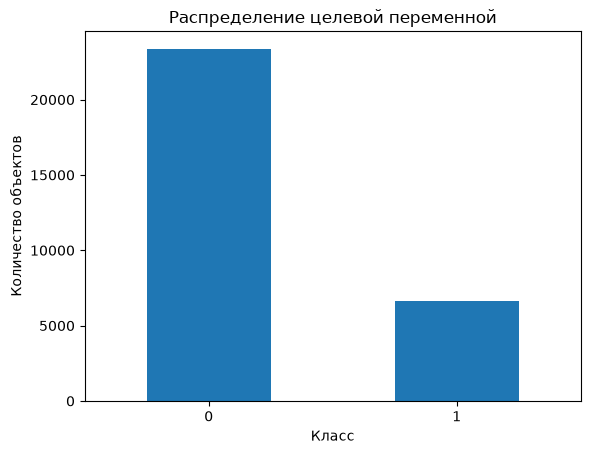

In [20]:
# Визуализируем распределение целевой переменной
target_counts.plot(kind="bar")

plt.title("Распределение целевой переменной")
plt.xlabel("Класс")
plt.ylabel("Количество объектов")
plt.xticks(rotation=0)
plt.show()

### Промежуточный вывод

Целевая переменная имеет умеренный дисбаланс классов: 77,88% клиентов относятся к классу 0 и 22,12% — к классу 1.
При дальнейшем разделении данных необходимо сохранить соотношение классов, а качество модели оценивать не только по Accuracy, но и по ROC-AUC, Precision, Recall и F1-score.

In [21]:
# Получаем общую статистическую информацию о числовых признаках
df.describe().T

,count,mean,std,min,25%,50%,75%,max
ID,30000.0,15000.500000,8660.398374,1.0,7500.75,15000.5,22500.25,30000.0
LIMIT_BAL,30000.0,167484.322667,129747.661567,10000.0,50000.00,140000.0,240000.00,1000000.0
SEX,30000.0,1.603733,0.489129,1.0,1.00,2.0,2.00,2.0
EDUCATION,30000.0,1.853133,0.790349,0.0,1.00,2.0,2.00,6.0
MARRIAGE,30000.0,1.551867,0.521970,0.0,1.00,2.0,2.00,3.0
AGE,30000.0,35.485500,9.217904,21.0,28.00,34.0,41.00,79.0
PAY_0,30000.0,-0.016700,1.123802,-2.0,-1.00,0.0,0.00,8.0
PAY_2,30000.0,-0.133767,1.197186,-2.0,-1.00,0.0,0.00,8.0
PAY_3,30000.0,-0.166200,1.196868,-2.0,-1.00,0.0,0.00,8.0
PAY_4,30000.0,-0.220667,1.169139,-2.0,-1.00,0.0,0.00,8.0


In [22]:
# Получаем распределение категориальных признаков
for column in ["SEX", "EDUCATION", "MARRIAGE"]:
    print(f"\n{column}:")
    print(df[column].value_counts().sort_index())


SEX:
SEX
1    11888
2    18112
Name: count, dtype: int64

EDUCATION:
EDUCATION
0       14
1    10585
2    14030
3     4917
4      123
5      280
6       51
Name: count, dtype: int64

MARRIAGE:
MARRIAGE
0       54
1    13659
2    15964
3      323
Name: count, dtype: int64


In [23]:
# Получаем распределение признаков задолженности по месяцам
pay_distribution = (
    df[pay_columns]
    .apply(lambda column: column.value_counts())
    .fillna(0)
    .astype(int)
    .sort_index()
)

pay_distribution

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,2759,3782,4085,4348,4546,4895
-1,5686,6050,5938,5687,5539,5740
0,14737,15730,15764,16455,16947,16286
1,3688,28,4,2,0,0
2,2667,3927,3819,3159,2626,2766
3,322,326,240,180,178,184
4,76,99,76,69,84,49
5,26,25,21,35,17,13
6,11,12,23,5,4,19
7,9,20,27,58,58,46


In [27]:
# Доля дефолтов в зависимости от статуса платежа
target = "default.payment.next.month"

default_rate_by_pay = pd.DataFrame({
    column: df.groupby(column)[target].mean()
    for column in pay_columns
}).sort_index()

(default_rate_by_pay * 100).round(1)

,PAY_0,PAY_2,PAY_3,PAY_4,PAY_5,PAY_6
-2,13.2,18.3,18.5,19.3,19.7,20.0
-1,16.8,16.0,15.6,15.9,16.2,17.0
0,12.8,15.9,17.5,18.3,18.9,18.8
1,33.9,17.9,25.0,50.0,NaN,NaN
2,69.1,55.6,51.6,52.3,54.2,50.7
3,75.8,61.7,57.5,61.1,63.5,64.1
4,68.4,50.5,57.9,66.7,60.7,63.3
5,50.0,60.0,57.1,51.4,58.8,53.8
6,54.5,75.0,60.9,40.0,75.0,73.7
7,77.8,60.0,81.5,82.8,82.8,82.6


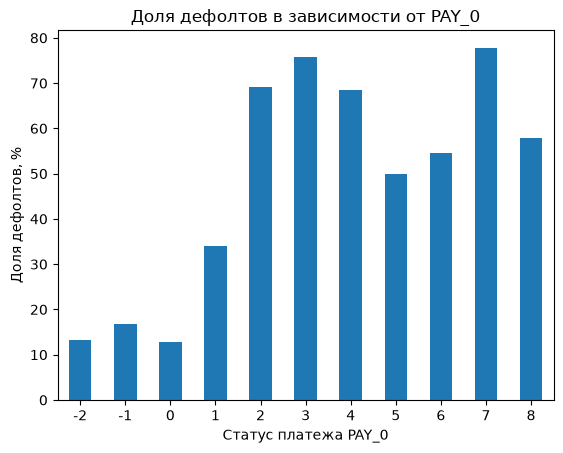

In [28]:
# визуализируем зависимость доли дефолтов от статуса платежа PAY_0
default_rate_pay0 = (
    df.groupby("PAY_0")["default.payment.next.month"]
    .mean()
    * 100
)

default_rate_pay0.plot(kind="bar")

plt.title("Доля дефолтов в зависимости от PAY_0")
plt.xlabel("Статус платежа PAY_0")
plt.ylabel("Доля дефолтов, %")
plt.xticks(rotation=0)
plt.show()

### Промежуточный вывод

В признаках `EDUCATION` и `MARRIAGE` встречаются редкие значения, которые не входят в основные описанные категории. Их необходимо будет учесть при предобработке данных.

По признакам `PAY_0`–`PAY_6` большинство наблюдений сосредоточено около значений -2, -1 и 0, а большие значения просрочки встречаются значительно реже.

Для `PAY_0` хорошо заметно, что при переходе от отсутствия выраженной просрочки к значениям 1–3 доля дефолтов существенно возрастает. Это указывает на сильную связь текущего платёжного статуса с целевой переменной.

Для значений `PAY_0` от 4 до 8 доля дефолтов изменяется неравномерно, однако такие категории содержат мало наблюдений, поэтому их значения следует интерпретировать осторожно.

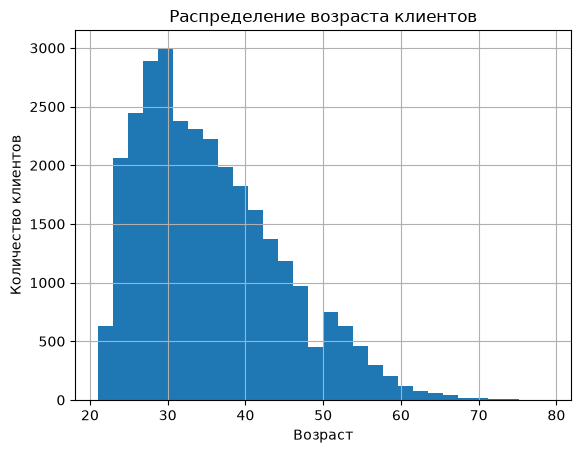

In [ ]:
# Анализ числовых признаков 

df["AGE"].hist(bins=30) # Гистограмма возраста клиентов

plt.title("Распределение возраста клиентов")
plt.xlabel("Возраст")
plt.ylabel("Количество клиентов")
plt.show()

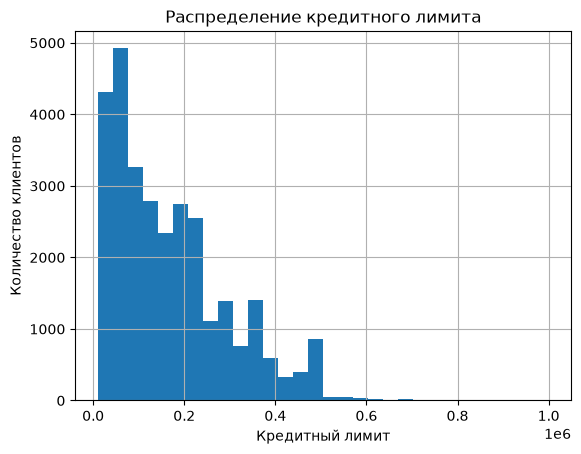

In [30]:
# Гистограмма кредитного лимита клиентов
df["LIMIT_BAL"].hist(bins=30)

plt.title("Распределение кредитного лимита")
plt.xlabel("Кредитный лимит")
plt.ylabel("Количество клиентов")
plt.show()

## Промежуточный вывод

Возраст клиентов имеет умеренно правостороннее распределение: большая часть наблюдений приходится на возраст примерно от 25 до 45 лет. Явных некорректных значений не обнаружено.

Распределение кредитного лимита заметно скошено вправо: большинство клиентов имеют относительно небольшие и средние лимиты, тогда как большие значения встречаются значительно реже. Это необходимо учитывать при дальнейшей предобработке и выборе модели.

In [31]:
# Анализ сумм счетов и платежей

bill_columns = [f"BILL_AMT{i}" for i in range(1, 7)] # Список признаков сумм счетов за последние 6 месяцев
payment_columns = [f"PAY_AMT{i}" for i in range(1, 7)] # Список признаков сумм платежей за последние 6 месяцев

amount_columns = bill_columns + payment_columns # Список всех признаков сумм счетов и платежей

amount_summary = pd.DataFrame({ # Сводная таблица по суммам счетов и платежей
    "mean": df[amount_columns].mean(),
    "median": df[amount_columns].median(),
    "min": df[amount_columns].min(),
    "max": df[amount_columns].max(),
    "zero_count": (df[amount_columns] == 0).sum(),
    "negative_count": (df[amount_columns] < 0).sum()
})

amount_summary.round(1)

,mean,median,min,max,zero_count,negative_count
BILL_AMT1,51223.3,22381.5,-165580.0,964511.0,2008,590
BILL_AMT2,49179.1,21200.0,-69777.0,983931.0,2506,669
BILL_AMT3,47013.2,20088.5,-157264.0,1664089.0,2870,655
BILL_AMT4,43262.9,19052.0,-170000.0,891586.0,3195,675
BILL_AMT5,40311.4,18104.5,-81334.0,927171.0,3506,655
BILL_AMT6,38871.8,17071.0,-339603.0,961664.0,4020,688
PAY_AMT1,5663.6,2100.0,0.0,873552.0,5249,0
PAY_AMT2,5921.2,2009.0,0.0,1684259.0,5396,0
PAY_AMT3,5225.7,1800.0,0.0,896040.0,5968,0
PAY_AMT4,4826.1,1500.0,0.0,621000.0,6408,0


## Промежуточный вывод

Признаки `BILL_AMT1–6` и `PAY_AMT1–6` имеют несимметричное распределение: у большинства клиентов значения относительно небольшие, но встречаются отдельные очень крупные суммы.

В `PAY_AMT1–6` много нулевых значений (примерно 17–24%), то есть в некоторые месяцы платеж не совершался. Отрицательных значений в суммах платежей нет.

В `BILL_AMT1–6` встречаются отрицательные значения. Таких наблюдений немного по сравнению со всем датасетом. Поскольку в описании датасета они не обозначены как ошибочные, на данном этапе мы их не удаляем и сохраняем без изменений.

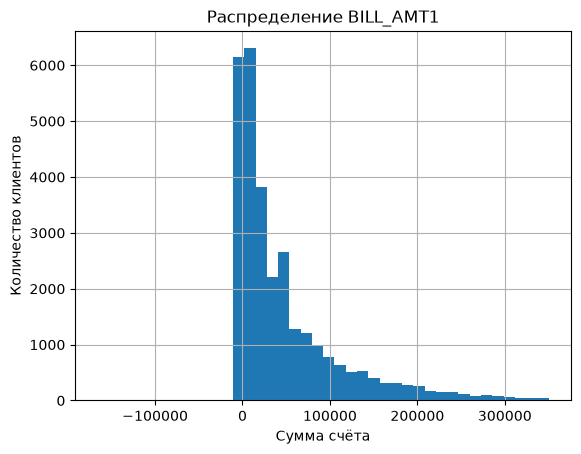

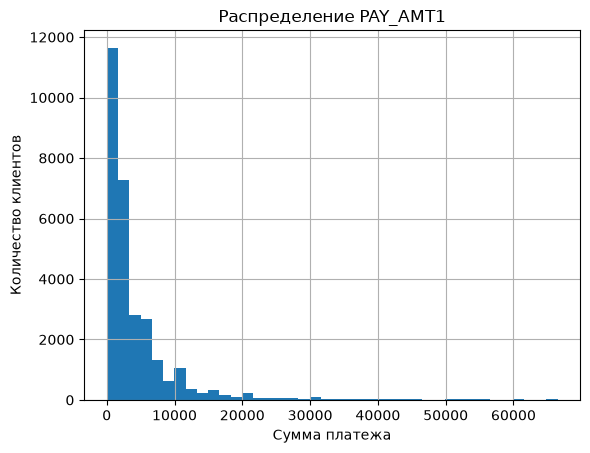

In [32]:
# Распределение сумм счетов и платежей
# Рассмотрим распределение суммы счёта (`BILL_AMT1`) и суммы платежа (`PAY_AMT1`) за последний месяц.

bill_limit = df["BILL_AMT1"].quantile(0.99)

df.loc[df["BILL_AMT1"] <= bill_limit, "BILL_AMT1"].hist(bins=40)
plt.title("Распределение BILL_AMT1")

plt.xlabel("Сумма счёта")
plt.ylabel("Количество клиентов")
plt.show()

pay_limit = df["PAY_AMT1"].quantile(0.99)

df.loc[df["PAY_AMT1"] <= pay_limit, "PAY_AMT1"].hist(bins=40)
plt.title("Распределение PAY_AMT1")

plt.xlabel("Сумма платежа")
plt.ylabel("Количество клиентов")
plt.show()

## Промежуточный вывод

Распределения `BILL_AMT1` и `PAY_AMT1` сильно скошены вправо: большинство клиентов имеют сравнительно небольшие значения, а крупные суммы встречаются значительно реже.

Для `PAY_AMT1` заметна высокая концентрация небольших и нулевых платежей. В `BILL_AMT1` присутствуют отрицательные значения, которые на данном этапе сохраняются без изменений.

Полученные распределения согласуются с общей статистикой признаков `BILL_AMT1–6` и `PAY_AMT1–6`.

In [35]:
# Сравнение медианных значений числовых признаков по классам целевой переменной
numeric_features = ["AGE", "LIMIT_BAL", "BILL_AMT1", "PAY_AMT1"]

df.groupby("default.payment.next.month")[numeric_features].median()

,AGE,LIMIT_BAL,BILL_AMT1,PAY_AMT1
default.payment.next.month,,,,
0,34.0,150000.0,23119.5,2459.5
1,34.0,90000.0,20185.0,1636.0


## Промежуточный вывод

У клиентов с дефолтом медианный кредитный лимит и сумма последнего платежа ниже. Медианный возраст между классами практически не отличается.

In [38]:
# Сравнение средних значений категориальных признаков по классам целевой переменной
categorical_features = ["SEX", "EDUCATION", "MARRIAGE"]
target = "default.payment.next.month"

for column in categorical_features:
    summary = df.groupby(column)[target].agg(["size", "mean"])

    summary.columns = ["Количество клиентов", "Доля дефолтов, %"]
    summary["Доля дефолтов, %"] = (summary["Доля дефолтов, %"] * 100).round(1)

    print(column)
    display(summary)

SEX


,Количество клиентов,"Доля дефолтов, %"
SEX,,
1,11888,24.2
2,18112,20.8


EDUCATION


,Количество клиентов,"Доля дефолтов, %"
EDUCATION,,
0,14,0.0
1,10585,19.2
2,14030,23.7
3,4917,25.2
4,123,5.7
5,280,6.4
6,51,15.7


MARRIAGE


,Количество клиентов,"Доля дефолтов, %"
MARRIAGE,,
0,54,9.3
1,13659,23.5
2,15964,20.9
3,323,26.0


## Итоговый вывод по EDA
Данные подходят для построения модели дефолта, но требуют предварительной обработки.
Наиболее информативными для дальнейшего моделирования выглядят признаки платёжной дисциплины и финансового поведения клиента. Категориальные признаки содержат редкие и нестандартные значения, которые необходимо привести к согласованному виду.

Денежные признаки имеют сильно несимметричные распределения, поэтому их предобработку следует выполнять с учётом выбросов и различий в масштабе.

Умеренный дисбаланс целевой переменной необходимо учитывать при разделении выборки и выборе метрик качества.